# Dayton, Ohio — Hourly Energy Consumption Forecasting with LSTM

**Dataset**: Hourly weather data (2006–2015) merged with hourly energy consumption (Dayton, OH).

**Target**: `mw` — electricity consumption in megawatts (hourly).

**Weather inputs**: `Temp_C`, `Dew_Point_C`, `RH_percent`, `Pressure_kPa`, `Wind_Dir_deg`, `Wind_Speed_mps`, `Visibility_km`, `Precip_cm`

**Engineered features**: cyclical time encodings · lag features (1 h – 168 h) · rolling statistics · day-of-week flags · weekend / weekday / working-day / non-working-day indicators · temperature × RH interaction

**Memory strategy**: training uses a `tf.keras.utils.Sequence` generator (no large pre-allocated array); val/test materialised once as float32.

**Anti-overfitting**: Dropout · Recurrent Dropout · BatchNorm · L2 · EarlyStopping · ReduceLROnPlateau

## 1. Install / Import Dependencies

In [21]:
# Uncomment to install on a fresh environment
# !pip install tensorflow scikit-learn pandas numpy matplotlib seaborn joblib

In [22]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    LSTM, Dense, Dropout, BatchNormalization, Bidirectional
)
from tensorflow.keras.callbacks import (
    EarlyStopping, ReduceLROnPlateau, ModelCheckpoint
)
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.regularizers import l2

import joblib

SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

print(f'TensorFlow : {tf.__version__}')
print(f'Pandas     : {pd.__version__}')
print(f'NumPy      : {np.__version__}')

TensorFlow : 2.21.0
Pandas     : 2.2.3
NumPy      : 2.1.3


## 2. Load Raw Data

Update the two paths below to match your environment.

In [23]:
ENERGY_PATH  = '../data/processed/FINAL_MERGED_DAY_LOAD_2006_2016.csv'
WEATHER_PATH = '../data/processed/weather_DAY_2006-2016.csv'

energy  = pd.read_csv(ENERGY_PATH,  parse_dates=['datetime'])
weather = pd.read_csv(WEATHER_PATH, parse_dates=['datetime'])

print(f'Energy  shape : {energy.shape}')
print(f'Weather shape : {weather.shape}')
print()
print('── Energy sample ──')
print(energy.head(4).to_string())
print()
print('── Weather sample ──')
print(weather.head(4).to_string())

Energy  shape : (78878, 2)
Weather shape : (78887, 9)

── Energy sample ──
       mw            datetime
0  1697.0 2006-01-01 05:00:00
1  1635.0 2006-01-01 06:00:00
2  1584.0 2006-01-01 07:00:00
3  1553.0 2006-01-01 08:00:00

── Weather sample ──
             datetime  Temp_C  Dew_Point_C  RH_percent  Pressure_kPa  Wind_Dir_deg  Wind_Speed_mps  Visibility_km  Precip_cm
0 2006-01-01 01:00:00     0.0         -2.2        85.0          97.3         280.0             6.1            6.4       0.03
1 2006-01-01 02:00:00    -0.6         -2.2        89.0          97.3         290.0             6.1            6.4       0.00
2 2006-01-01 03:00:00    -0.6         -2.2        89.0          97.4         300.0             7.7            6.4       0.00
3 2006-01-01 04:00:00    -0.6         -2.2        89.0          97.4         300.0             6.7            2.4       0.00


## 3. Merge & Clean

Both files are already at hourly granularity. Timestamps are rounded to the nearest hour before an inner-join to absorb any sub-minute offsets.

In [24]:
energy['datetime']  = energy['datetime'].dt.round('h')
weather['datetime'] = weather['datetime'].dt.round('h')

df = pd.merge(energy, weather, on='datetime', how='inner')
df = df.sort_values('datetime').reset_index(drop=True)

print(f'Merged shape : {df.shape}')
print(f'Date range   : {df["datetime"].min()}  →  {df["datetime"].max()}')
print()
print('Missing values per column:')
print(df.isnull().sum())

Merged shape : (78878, 10)
Date range   : 2006-01-01 05:00:00  →  2015-12-31 23:00:00

Missing values per column:
mw                0
datetime          0
Temp_C            0
Dew_Point_C       0
RH_percent        0
Pressure_kPa      0
Wind_Dir_deg      0
Wind_Speed_mps    0
Visibility_km     0
Precip_cm         0
dtype: int64


In [25]:
# Linear interpolation for small gaps; forward/back fill any residuals
df = df.interpolate(method='linear', limit=3).ffill().bfill()

assert df.isnull().sum().sum() == 0, 'NaNs remain — check your data!'
print('✓ No missing values after cleaning.')
print(f'Final shape : {df.shape}')

✓ No missing values after cleaning.
Final shape : (78878, 10)


## 4. Feature Engineering

| Category | Features |
|---|---|
| Cyclical time (8) | sin/cos of hour, day-of-week, month, day-of-year |
| Day-type flags (5) | `is_weekend`, `is_weekday`, `is_working_day`, `is_non_working_day`, `is_business_hour` |
| Lag features (6) | 1 h, 2 h, 3 h, 24 h, 48 h, 168 h |
| Rolling stats (4) | 24 h & 168 h mean/std (shifted by 1 — no leakage) |
| Weather interaction (1) | `temp_rh_interaction` = Temp_C × RH_percent |
| Raw weather (8) | Temp_C, Dew_Point_C, RH_percent, Pressure_kPa, Wind_Dir_deg, Wind_Speed_mps, Visibility_km, Precip_cm |

In [26]:
dt = df['datetime']

# ── 4.1 Cyclical time encodings ──────────────────────────────────────────────
df['hour_sin']      = np.sin(2 * np.pi * dt.dt.hour       / 24)
df['hour_cos']      = np.cos(2 * np.pi * dt.dt.hour       / 24)
df['dayofweek_sin'] = np.sin(2 * np.pi * dt.dt.dayofweek  / 7)
df['dayofweek_cos'] = np.cos(2 * np.pi * dt.dt.dayofweek  / 7)
df['month_sin']     = np.sin(2 * np.pi * dt.dt.month      / 12)
df['month_cos']     = np.cos(2 * np.pi * dt.dt.month      / 12)
df['dayofyear_sin'] = np.sin(2 * np.pi * dt.dt.dayofyear  / 365)
df['dayofyear_cos'] = np.cos(2 * np.pi * dt.dt.dayofyear  / 365)

# ── 4.2 Day-type binary flags ─────────────────────────────────────────────────
df['is_weekend']         = (dt.dt.dayofweek >= 5).astype(int)
df['is_weekday']         = (dt.dt.dayofweek <  5).astype(int)
df['is_working_day']     = (dt.dt.dayofweek <  5).astype(int)
df['is_non_working_day'] = (dt.dt.dayofweek >= 5).astype(int)
df['is_business_hour']   = (
    (dt.dt.hour >= 8) & (dt.dt.hour <= 18) & (dt.dt.dayofweek < 5)
).astype(int)

# ── 4.3 Lag features ──────────────────────────────────────────────────────────
for lag in [1, 2, 3, 24, 48, 168]:
    df[f'lag_{lag}h'] = df['mw'].shift(lag)

# ── 4.4 Rolling statistics (shift by 1 to prevent data leakage) ───────────────
for window in [24, 168]:
    shifted = df['mw'].shift(1)
    df[f'roll_mean_{window}h'] = shifted.rolling(window).mean()
    df[f'roll_std_{window}h']  = shifted.rolling(window).std()

# ── 4.5 Weather interaction ────────────────────────────────────────────────────
df['temp_rh_interaction'] = df['Temp_C'] * df['RH_percent']

# Drop NaN rows created by lags / rolling windows
df.dropna(inplace=True)
df.reset_index(drop=True, inplace=True)

FEATURE_COLS = [
    'Temp_C', 'Dew_Point_C', 'RH_percent', 'Pressure_kPa',
    'Wind_Dir_deg', 'Wind_Speed_mps', 'Visibility_km', 'Precip_cm',
    'hour_sin', 'hour_cos', 'dayofweek_sin', 'dayofweek_cos',
    'month_sin', 'month_cos', 'dayofyear_sin', 'dayofyear_cos',
    'is_weekend', 'is_weekday', 'is_working_day', 'is_non_working_day',
    'is_business_hour',
    'lag_1h', 'lag_2h', 'lag_3h', 'lag_24h', 'lag_48h', 'lag_168h',
    'roll_mean_24h', 'roll_std_24h',
    'roll_mean_168h', 'roll_std_168h',
    'temp_rh_interaction',
]
TARGET_COL = 'mw'

print(f'Shape after feature engineering : {df.shape}')
print(f'Number of features              : {len(FEATURE_COLS)}')

Shape after feature engineering : (78710, 34)
Number of features              : 32


## 5. Exploratory Data Analysis

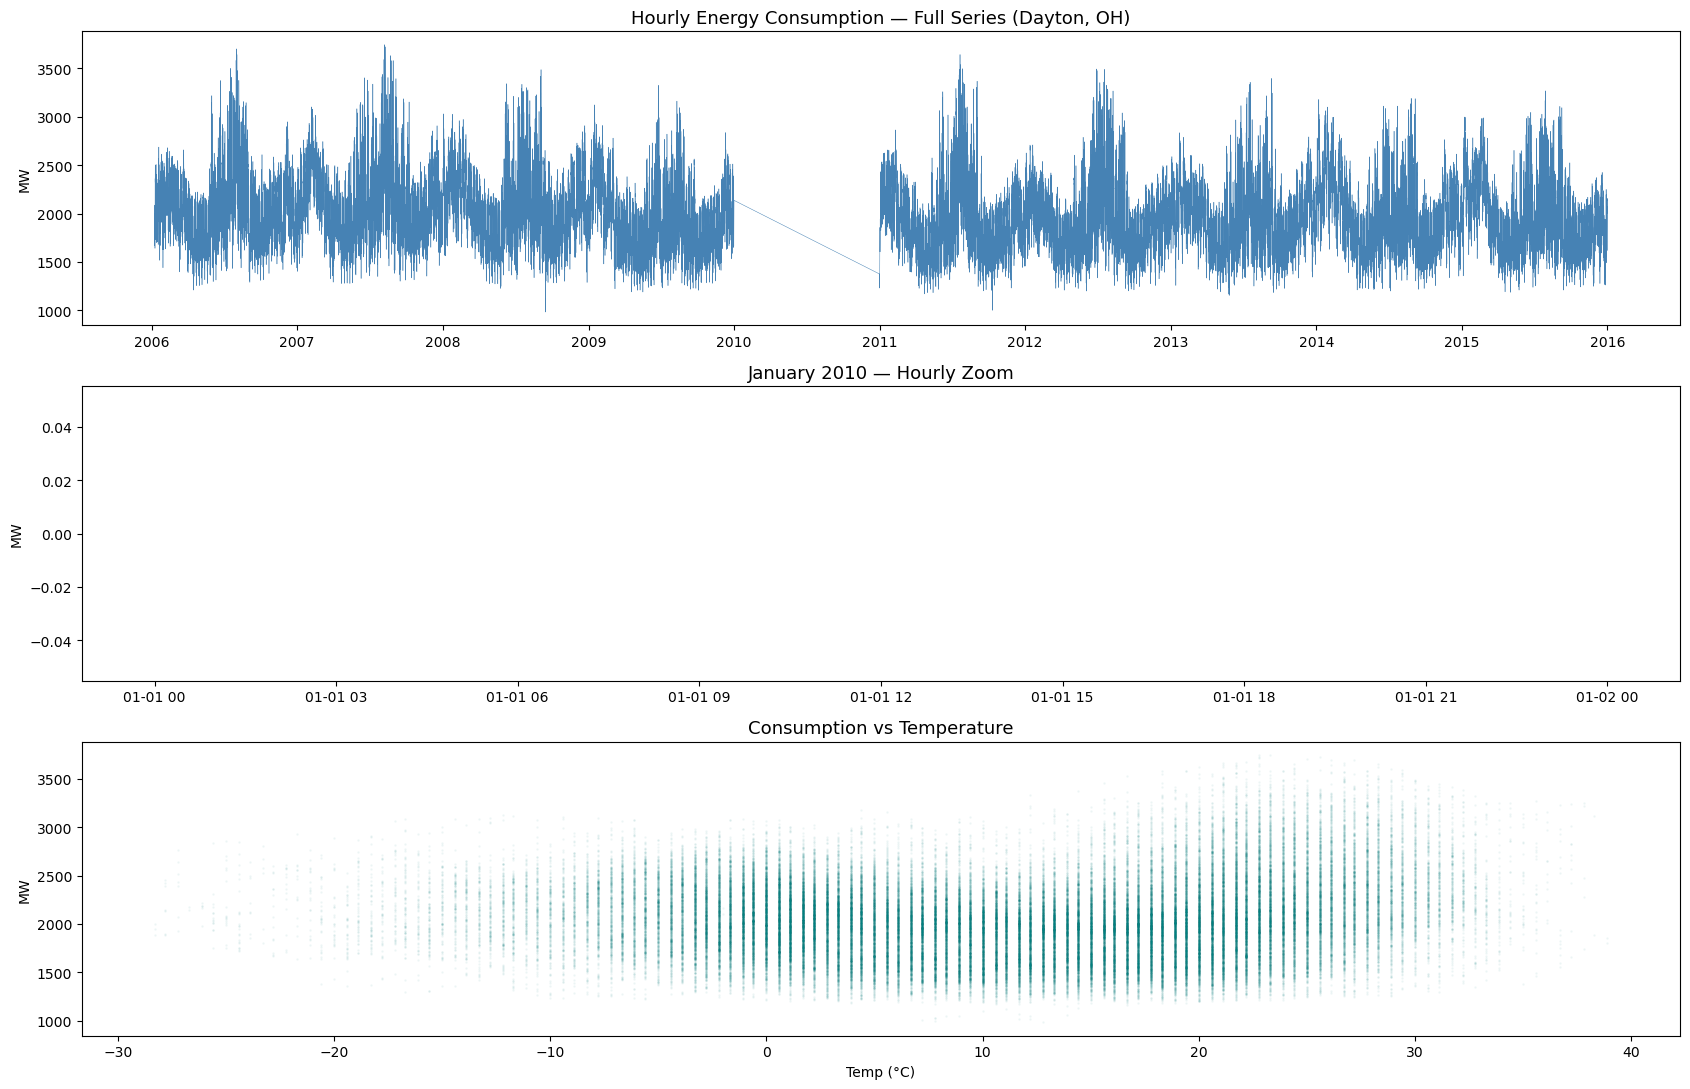

EDA overview saved → eda_overview.png


In [27]:
fig, axes = plt.subplots(3, 1, figsize=(17, 11))

axes[0].plot(df['datetime'], df['mw'], linewidth=0.35, color='steelblue')
axes[0].set_title('Hourly Energy Consumption — Full Series (Dayton, OH)', fontsize=13)
axes[0].set_ylabel('MW')

mask = (df['datetime'] >= '2010-01-01') & (df['datetime'] < '2010-02-01')
axes[1].plot(df.loc[mask, 'datetime'], df.loc[mask, 'mw'],
             color='darkorange', linewidth=0.9)
axes[1].set_title('January 2010 — Hourly Zoom', fontsize=13)
axes[1].set_ylabel('MW')

axes[2].scatter(df['Temp_C'], df['mw'], alpha=0.04, s=1, color='teal')
axes[2].set_title('Consumption vs Temperature', fontsize=13)
axes[2].set_xlabel('Temp (°C)')
axes[2].set_ylabel('MW')

plt.tight_layout()
plt.savefig('../outputs/figures/eda_overview.png', dpi=120, bbox_inches='tight')
plt.show()
print('EDA overview saved → eda_overview.png')

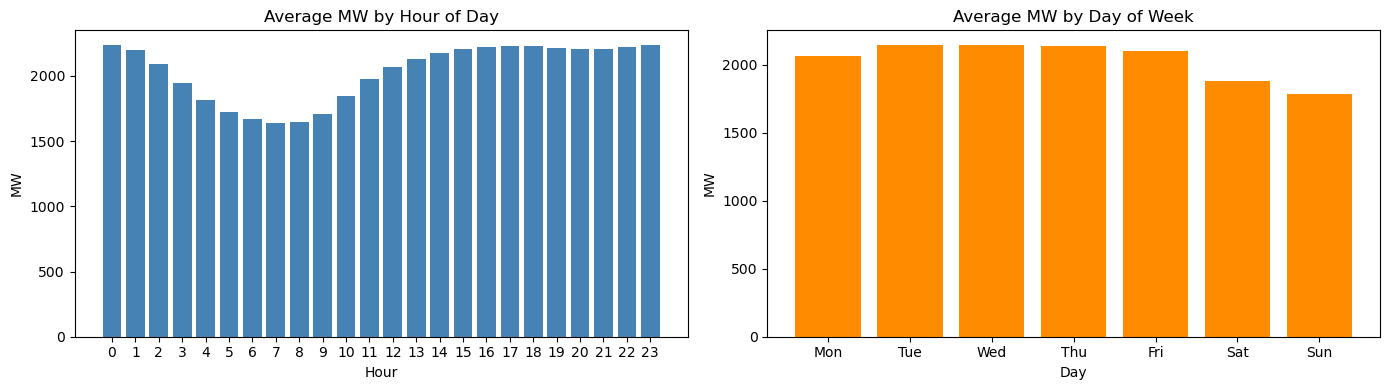

Temporal patterns saved → eda_temporal_patterns.png


In [28]:
hourly_avg = df.groupby(df['datetime'].dt.hour)['mw'].mean()
day_avg    = df.groupby(df['datetime'].dt.dayofweek)['mw'].mean()
day_labels = ['Mon','Tue','Wed','Thu','Fri','Sat','Sun']

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].bar(hourly_avg.index, hourly_avg.values, color='steelblue', width=0.8)
axes[0].set_title('Average MW by Hour of Day')
axes[0].set_xlabel('Hour')
axes[0].set_ylabel('MW')
axes[0].set_xticks(range(24))

axes[1].bar(day_avg.index, day_avg.values, color='darkorange', width=0.8)
axes[1].set_title('Average MW by Day of Week')
axes[1].set_xlabel('Day')
axes[1].set_ylabel('MW')
axes[1].set_xticks(range(7))
axes[1].set_xticklabels(day_labels)

plt.tight_layout()
plt.savefig('../outputs/figures/eda_temporal_patterns.png', dpi=120, bbox_inches='tight')
plt.show()
print('Temporal patterns saved → eda_temporal_patterns.png')

## 6. Correlation Analysis

Six views covering every feature group:
1. Weather features vs target
2. Lag features vs target
3. Rolling statistics vs target
4. Day-type & cyclical features vs target
5. Bar chart of |correlation| with `mw` for all features
6. Full lower-triangle heatmap across all 32 features

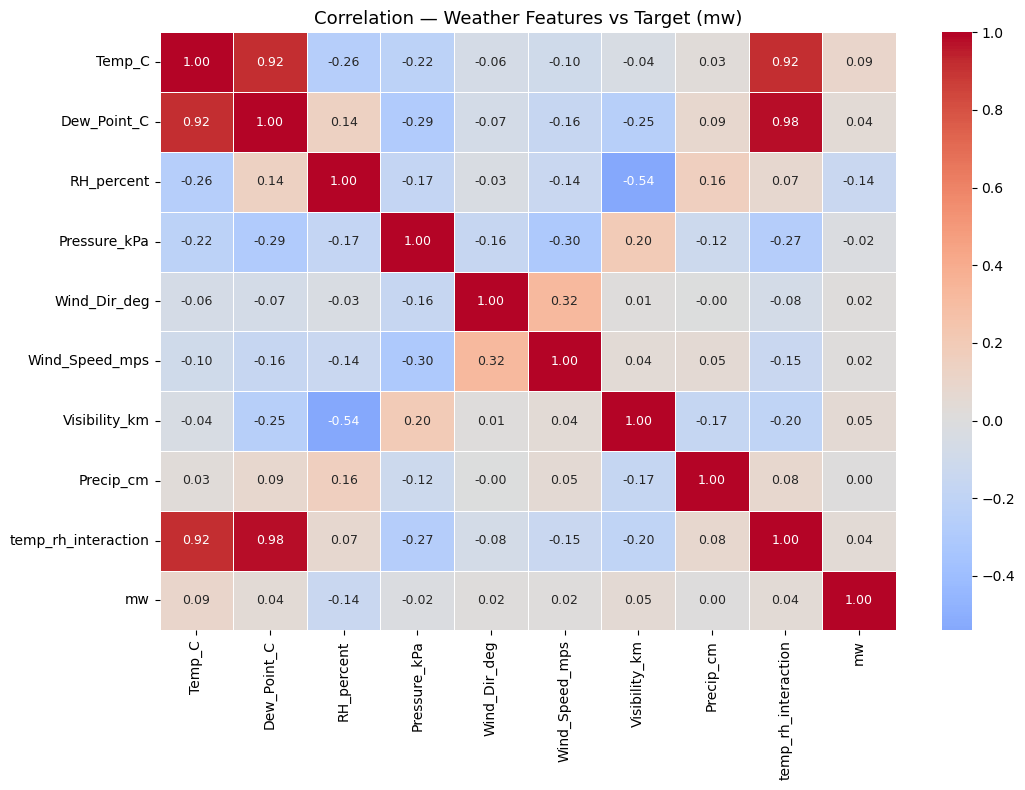

In [29]:
# ── 6.1 Weather features vs target ──────────────────────────────────────────
weather_cols = ['Temp_C','Dew_Point_C','RH_percent','Pressure_kPa',
                'Wind_Dir_deg','Wind_Speed_mps','Visibility_km',
                'Precip_cm','temp_rh_interaction','mw']

plt.figure(figsize=(11, 8))
sns.heatmap(df[weather_cols].corr(), annot=True, fmt='.2f',
            cmap='coolwarm', center=0, linewidths=0.5, annot_kws={'size': 9})
plt.title('Correlation — Weather Features vs Target (mw)', fontsize=13)
plt.tight_layout()
plt.savefig('../outputs/figures/corr_weather.png', dpi=120, bbox_inches='tight')
plt.show()

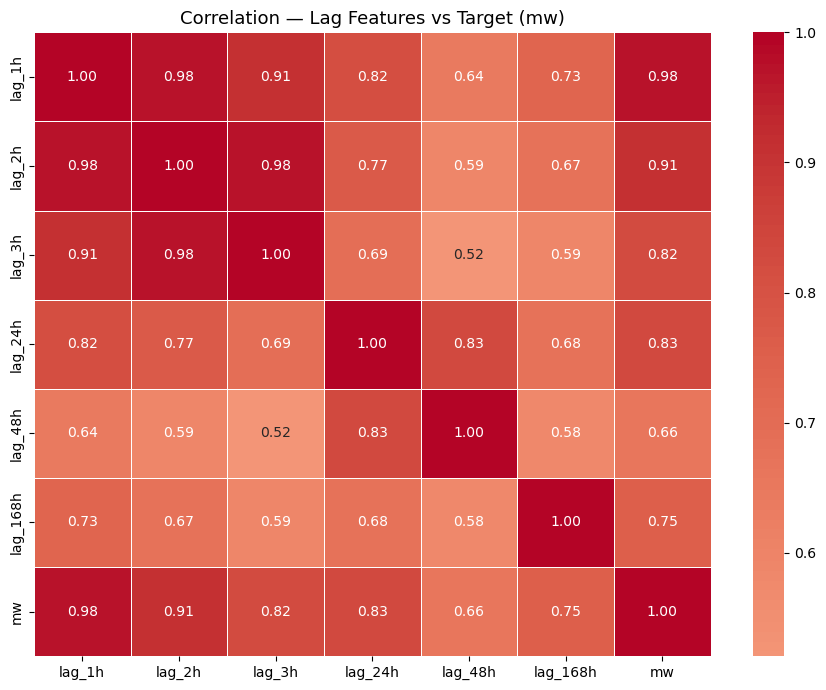

In [30]:
# ── 6.2 Lag features vs target ───────────────────────────────────────────────
lag_cols = ['lag_1h','lag_2h','lag_3h','lag_24h','lag_48h','lag_168h','mw']

plt.figure(figsize=(9, 7))
sns.heatmap(df[lag_cols].corr(), annot=True, fmt='.2f',
            cmap='coolwarm', center=0, linewidths=0.5)
plt.title('Correlation — Lag Features vs Target (mw)', fontsize=13)
plt.tight_layout()
plt.savefig('../outputs/figures/corr_lags.png', dpi=120, bbox_inches='tight')
plt.show()

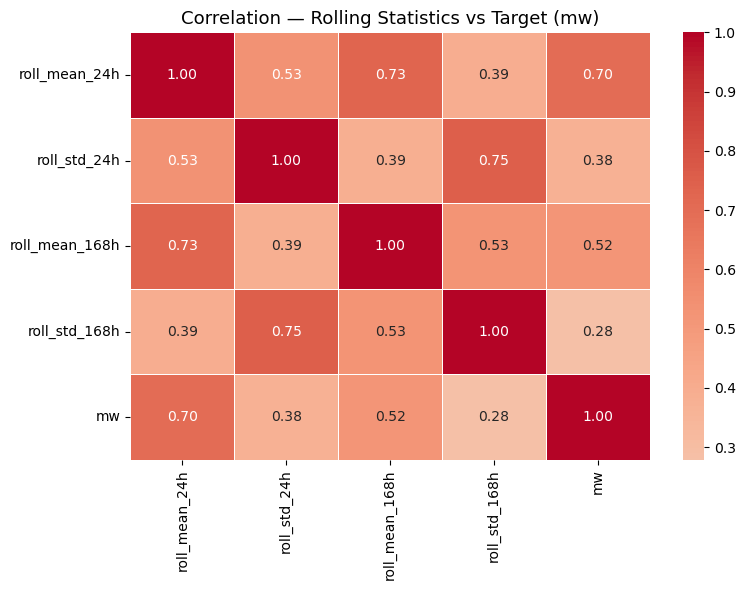

In [31]:
# ── 6.3 Rolling statistics vs target ─────────────────────────────────────────
roll_cols = ['roll_mean_24h','roll_std_24h',
             'roll_mean_168h','roll_std_168h','mw']

plt.figure(figsize=(8, 6))
sns.heatmap(df[roll_cols].corr(), annot=True, fmt='.2f',
            cmap='coolwarm', center=0, linewidths=0.5)
plt.title('Correlation — Rolling Statistics vs Target (mw)', fontsize=13)
plt.tight_layout()
plt.savefig('../outputs/figures/corr_rolling.png', dpi=120, bbox_inches='tight')
plt.show()

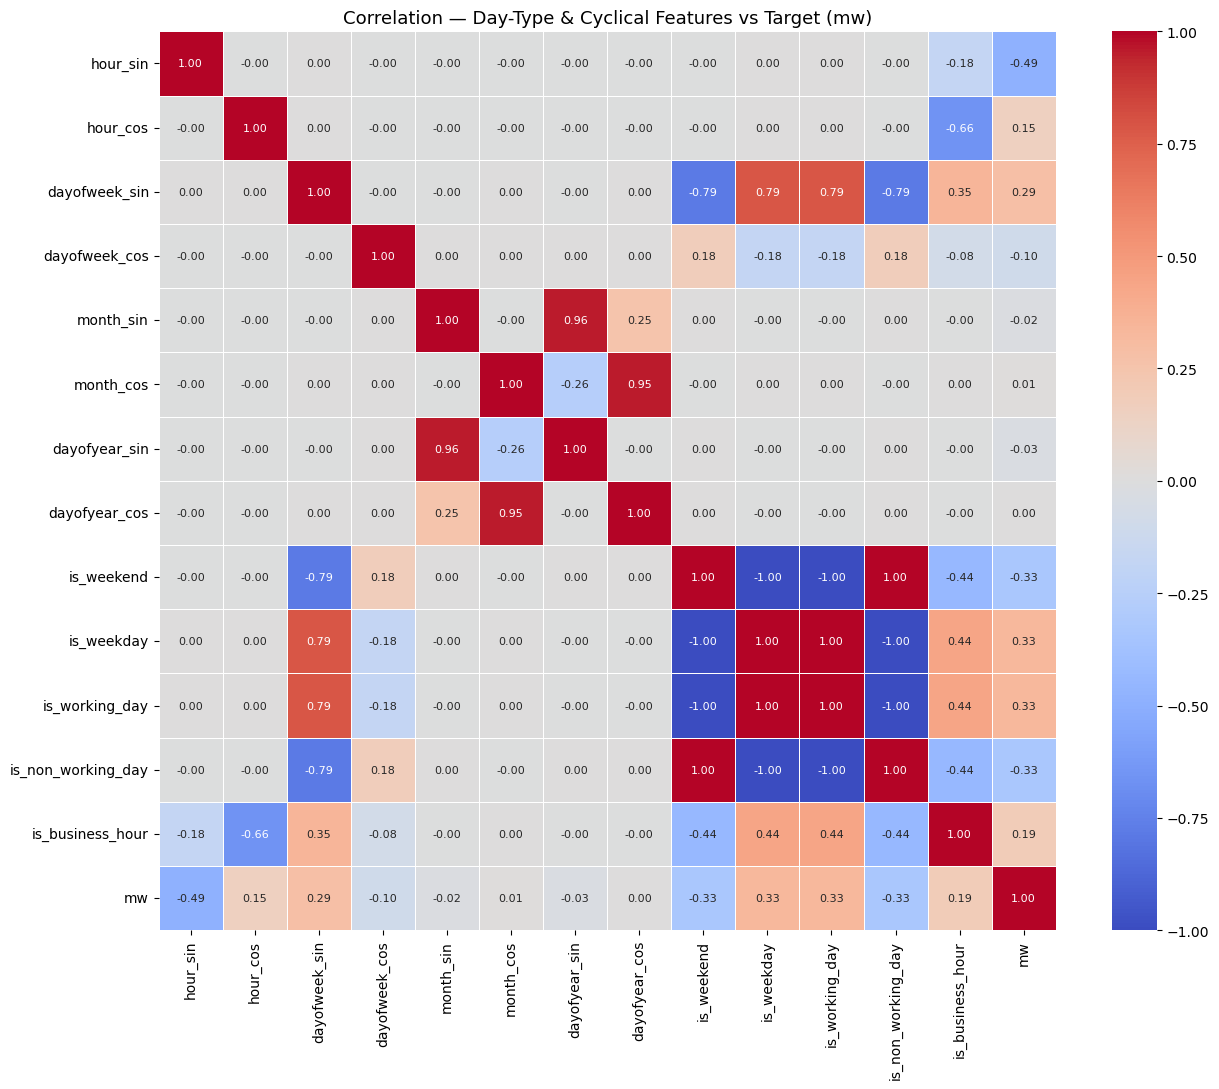

In [32]:
# ── 6.4 Day-type & cyclical features vs target ───────────────────────────────
daytype_cols = [
    'hour_sin','hour_cos',
    'dayofweek_sin','dayofweek_cos',
    'month_sin','month_cos',
    'dayofyear_sin','dayofyear_cos',
    'is_weekend','is_weekday',
    'is_working_day','is_non_working_day',
    'is_business_hour','mw'
]

plt.figure(figsize=(13, 11))
sns.heatmap(df[daytype_cols].corr(), annot=True, fmt='.2f',
            cmap='coolwarm', center=0, linewidths=0.5, annot_kws={'size': 8})
plt.title('Correlation — Day-Type & Cyclical Features vs Target (mw)', fontsize=13)
plt.tight_layout()
plt.savefig('../outputs/figures/corr_daytype.png', dpi=120, bbox_inches='tight')
plt.show()

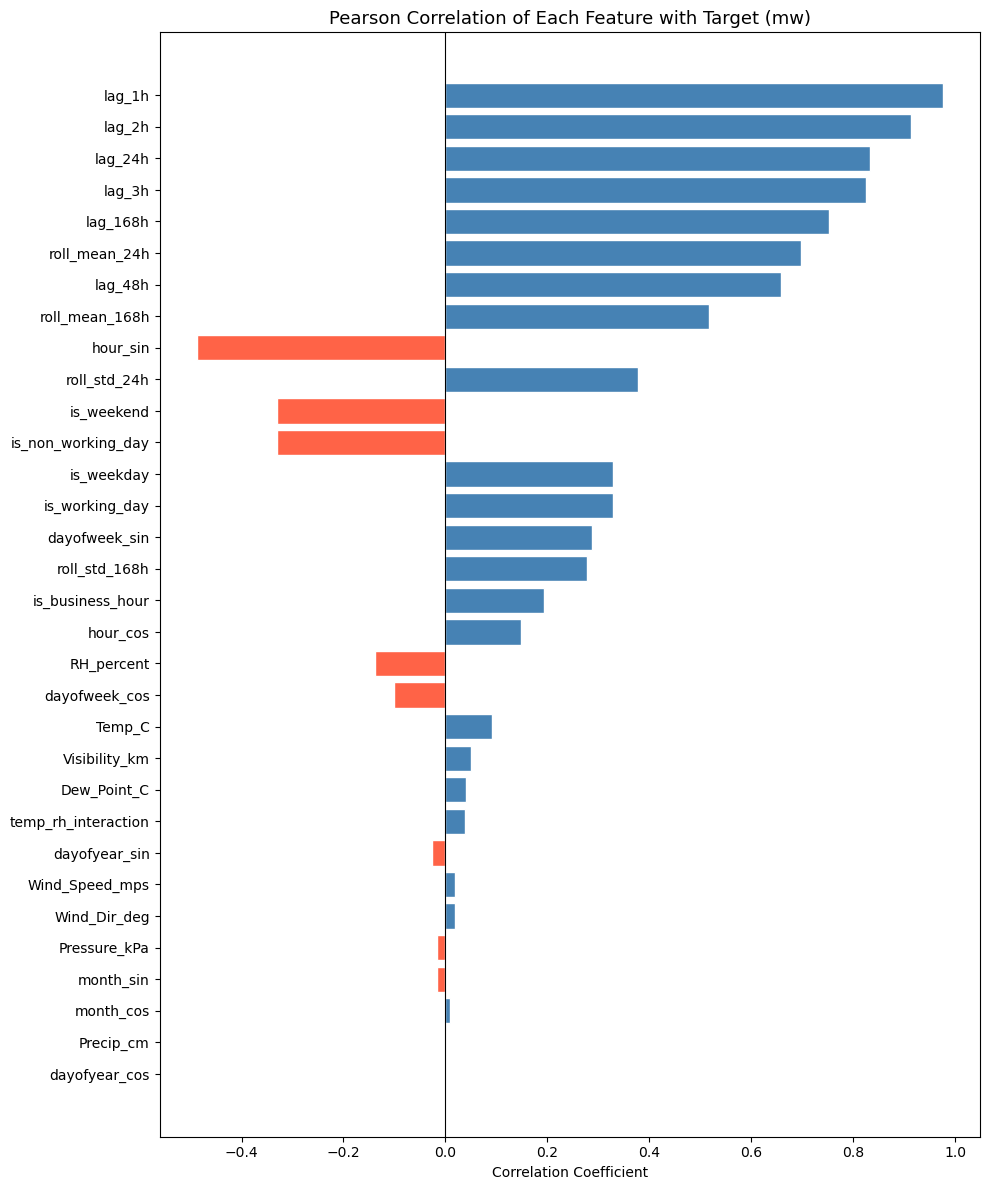

Blue = positive correlation, Red = negative correlation


In [33]:
# ── 6.5 Bar chart: |correlation| of every feature with target ────────────────
corr_target = df[FEATURE_COLS + [TARGET_COL]].corr()[TARGET_COL].drop(TARGET_COL)
corr_sorted = corr_target.abs().sort_values(ascending=True)
bar_colors  = ['tomato' if corr_target[f] < 0 else 'steelblue'
               for f in corr_sorted.index]

plt.figure(figsize=(10, 12))
plt.barh(corr_sorted.index, corr_target[corr_sorted.index],
         color=bar_colors, edgecolor='white', height=0.8)
plt.axvline(0, color='black', linewidth=0.8)
plt.title('Pearson Correlation of Each Feature with Target (mw)', fontsize=13)
plt.xlabel('Correlation Coefficient')
plt.tight_layout()
plt.savefig('../outputs/figures/corr_all_features_bar.png', dpi=120, bbox_inches='tight')
plt.show()
print('Blue = positive correlation, Red = negative correlation')

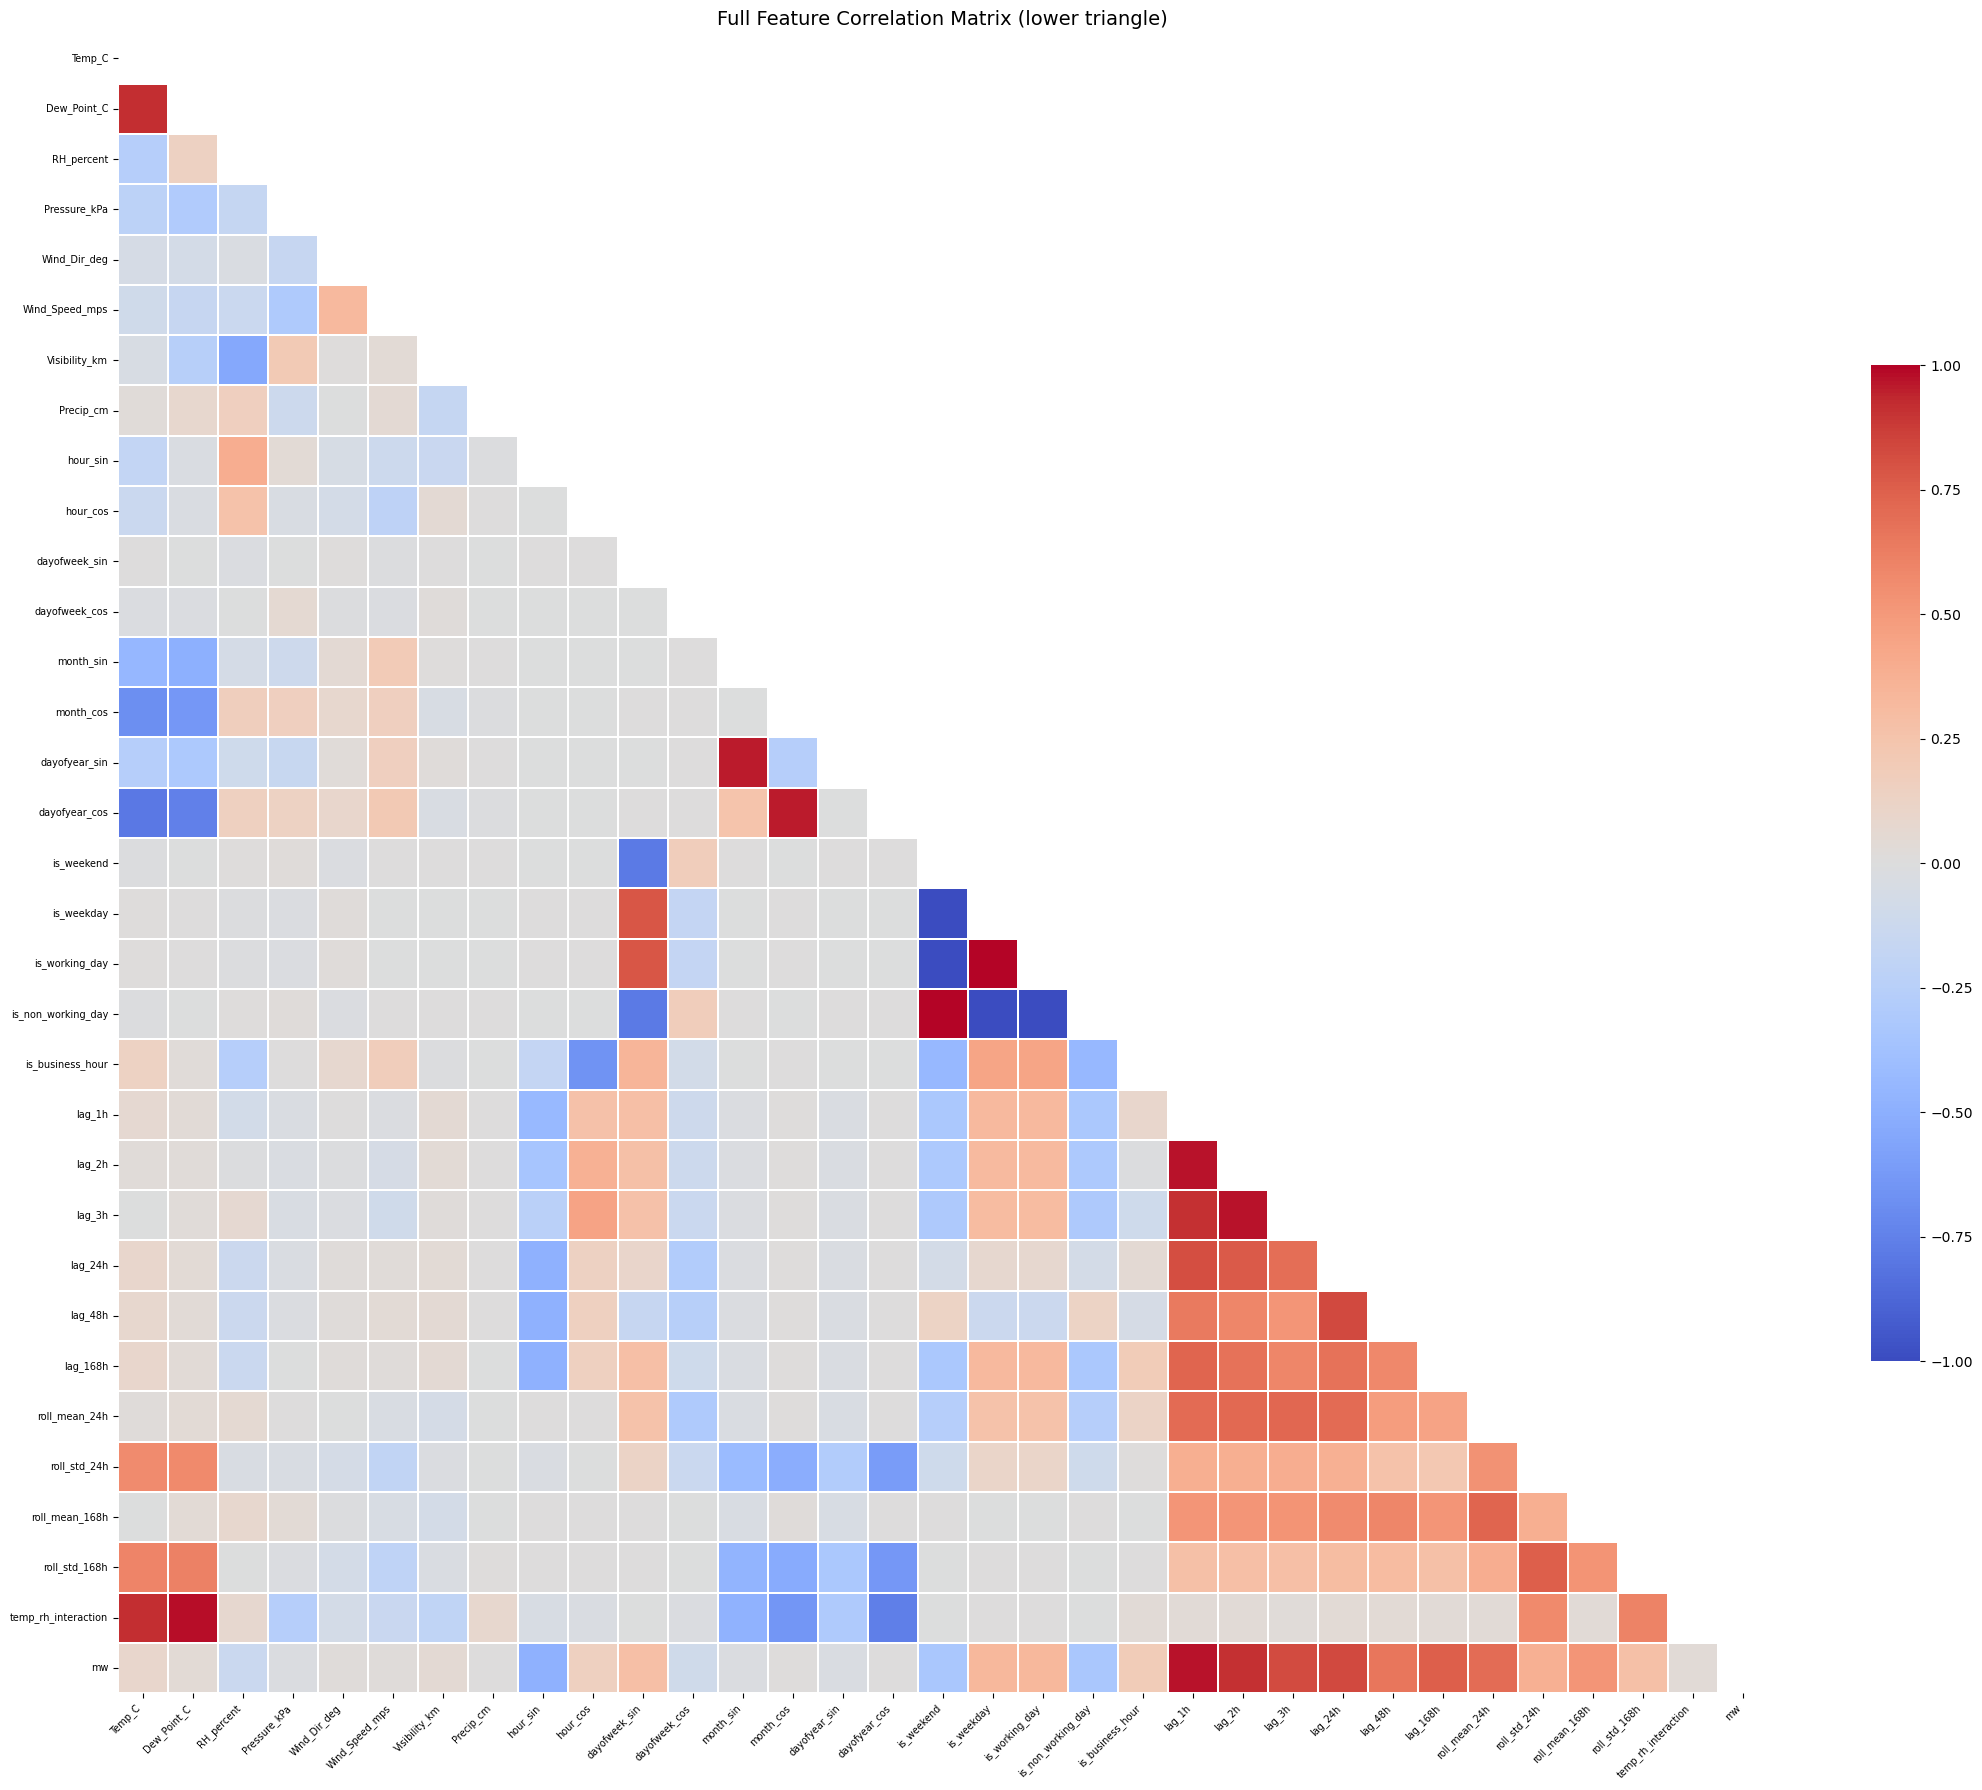

Full heatmap saved → corr_full_heatmap.png


In [34]:
# ── 6.6 Full lower-triangle heatmap (all 32 features + target) ───────────────
full_corr = df[FEATURE_COLS + [TARGET_COL]].corr()
mask      = np.triu(np.ones_like(full_corr, dtype=bool))

plt.figure(figsize=(22, 18))
sns.heatmap(full_corr, mask=mask, annot=False,
            cmap='coolwarm', center=0, linewidths=0.2,
            cbar_kws={'shrink': 0.6})
plt.title('Full Feature Correlation Matrix (lower triangle)', fontsize=14)
plt.xticks(rotation=45, ha='right', fontsize=7)
plt.yticks(fontsize=7)
plt.tight_layout()
plt.savefig('../outputs/figures/corr_full_heatmap.png', dpi=120, bbox_inches='tight')
plt.show()
print('Full heatmap saved → corr_full_heatmap.png')

## 7. Train / Validation / Test Split

Chronological **70 / 10 / 20** split — no random shuffling (time series).

In [35]:
n         = len(df)
train_end = int(n * 0.70)
val_end   = int(n * 0.80)

train_df = df.iloc[:train_end]
val_df   = df.iloc[train_end:val_end]
test_df  = df.iloc[val_end:]

print(f'Train : {len(train_df):>7,} rows  '
      f'({train_df["datetime"].min().date()}  →  {train_df["datetime"].max().date()})')
print(f'Val   : {len(val_df):>7,} rows  '
      f'({val_df["datetime"].min().date()}   →  {val_df["datetime"].max().date()})')
print(f'Test  : {len(test_df):>7,} rows  '
      f'({test_df["datetime"].min().date()}  →  {test_df["datetime"].max().date()})')

Train :  55,097 rows  (2006-01-08  →  2013-04-22)
Val   :   7,871 rows  (2013-04-22   →  2014-03-16)
Test  :  15,742 rows  (2014-03-16  →  2015-12-31)


## 8. Scaling

> **Data-leakage rule**: scalers are fit **only** on the training set.  
> Arrays are cast to **float32** immediately — this halves memory vs float64 with no meaningful loss of precision for neural-network training.

In [36]:
feature_scaler = StandardScaler()
target_scaler  = StandardScaler()

X_train = feature_scaler.fit_transform(train_df[FEATURE_COLS]).astype(np.float32)
X_val   = feature_scaler.transform(val_df[FEATURE_COLS]).astype(np.float32)
X_test  = feature_scaler.transform(test_df[FEATURE_COLS]).astype(np.float32)

y_train = target_scaler.fit_transform(train_df[[TARGET_COL]]).astype(np.float32)
y_val   = target_scaler.transform(val_df[[TARGET_COL]]).astype(np.float32)
y_test  = target_scaler.transform(test_df[[TARGET_COL]]).astype(np.float32)

print('Scaling complete (float32).  Shapes:')
print(f'  X_train : {X_train.shape}  |  y_train : {y_train.shape}')
print(f'  X_val   : {X_val.shape}    |  y_val   : {y_val.shape}')
print(f'  X_test  : {X_test.shape}   |  y_test  : {y_test.shape}')
print()
print('Raw array memory (float32):')
print(f'  X_train : {X_train.nbytes/1e6:.1f} MB')
print(f'  X_val   : {X_val.nbytes/1e6:.1f} MB')
print(f'  X_test  : {X_test.nbytes/1e6:.1f} MB')

Scaling complete (float32).  Shapes:
  X_train : (55097, 32)  |  y_train : (55097, 1)
  X_val   : (7871, 32)    |  y_val   : (7871, 1)
  X_test  : (15742, 32)   |  y_test  : (15742, 1)

Raw array memory (float32):
  X_train : 7.1 MB
  X_val   : 1.0 MB
  X_test  : 2.0 MB


## 9. Memory-Efficient Sequence Handling

LSTM needs 3-D input `(samples, timesteps, features)`. Pre-building the full training sequence array would require ~1.4 GB — triggering a `MemoryError` on most laptops.

**Strategy**:
- **Training** → `TimeSeriesGenerator` (`tf.keras.utils.Sequence` subclass).  
  Sequences are sliced batch-by-batch at call time; peak extra RAM ≈ `batch_size × 168 × 32 × 4 B` ≈ 5 MB.
- **Val / Test** → `create_sequences_float32()` materialises the array once (smaller splits, ~160 MB total).  
  A guard raises a clear error before attempting allocation if the estimate exceeds 1 GB.

In [37]:
SEQ_LEN    = 168   # 1-week look-back window
BATCH_SIZE = 256   # moderate batch keeps per-step memory low


class TimeSeriesGenerator(tf.keras.utils.Sequence):
    """
    Yields (X_batch, y_batch) on-the-fly from a pre-scaled 2-D array.
    No full (N x SEQ_LEN x FEATURES) array is ever allocated.
    """
    def __init__(self, X, y, seq_len, batch_size, shuffle=False):
        self.X, self.y  = X, y
        self.seq_len    = seq_len
        self.batch_size = batch_size
        self.shuffle    = shuffle
        self.indices    = np.arange(seq_len, len(X))
        if shuffle:
            np.random.shuffle(self.indices)

    def __len__(self):
        return int(np.ceil(len(self.indices) / self.batch_size))

    def __getitem__(self, batch_idx):
        idx = self.indices[
            batch_idx * self.batch_size : (batch_idx + 1) * self.batch_size
        ]
        X_batch = np.stack([self.X[i - self.seq_len : i] for i in idx])
        y_batch = self.y[idx]
        return X_batch, y_batch

    def on_epoch_end(self):
        if self.shuffle:
            np.random.shuffle(self.indices)


def create_sequences_float32(X, y, seq_len):
    """
    Materialise sequences as float32 (use for val/test only).
    Raises MemoryError with a helpful message if estimate > 1 GB.
    """
    n_seq, n_feat = len(X) - seq_len, X.shape[1]
    est_mb = n_seq * seq_len * n_feat * 4 / 1e6
    if est_mb > 1000:
        raise MemoryError(
            f'Estimated array {est_mb:.0f} MB > 1 GB. '
            'Use TimeSeriesGenerator instead.'
        )
    xs = np.empty((n_seq, seq_len, n_feat), dtype=np.float32)
    ys = np.empty((n_seq, 1),               dtype=np.float32)
    for k, i in enumerate(range(seq_len, len(X))):
        xs[k] = X[i - seq_len : i]
        ys[k] = y[i]
    return xs, ys


# ── Build generator + materialise val/test ─────────────────────────────────
train_gen = TimeSeriesGenerator(X_train, y_train, SEQ_LEN, BATCH_SIZE)

print('Materialising val sequences  (float32) ...')
X_vl_seq, y_vl_seq = create_sequences_float32(X_val,  y_val,  SEQ_LEN)
print('Materialising test sequences (float32) ...')
X_te_seq, y_te_seq = create_sequences_float32(X_test, y_test, SEQ_LEN)

print()
print(f'Train generator : {len(train_gen)} batches '
      f'({len(train_gen.indices):,} sequences, on-the-fly)')
print(f'Val  array      : {X_vl_seq.shape}  '
      f'({X_vl_seq.nbytes/1e6:.1f} MB)')
print(f'Test array      : {X_te_seq.shape}  '
      f'({X_te_seq.nbytes/1e6:.1f} MB)')

Materialising val sequences  (float32) ...
Materialising test sequences (float32) ...

Train generator : 215 batches (54,929 sequences, on-the-fly)
Val  array      : (7703, 168, 32)  (165.6 MB)
Test array      : (15574, 168, 32)  (334.9 MB)


## 10. Build the LSTM Model

| Anti-overfitting technique | Detail |
|---|---|
| Bidirectional LSTM | Captures forward + backward context |
| Dropout 0.30 | Applied after each LSTM block |
| Recurrent Dropout 0.20 | Regularises recurrent weight updates |
| BatchNormalization | Stabilises & speeds training |
| L2 kernel regularisation 1e-4 | Penalises large weights |
| EarlyStopping patience=10 | Restores best weights on val plateau |
| ReduceLROnPlateau | Halves LR after 5 stagnant epochs |
| Huber loss | Robust to MW outlier spikes |

In [38]:
N_FEATURES = X_train.shape[1]   # 32


def build_model(seq_len, n_features,
                units_1=128, units_2=64,
                dropout_rate=0.30, rec_dropout=0.20,
                l2_reg=1e-4, lr=1e-3):
    model = Sequential([
        Bidirectional(
            LSTM(units_1, return_sequences=True,
                 dropout=dropout_rate, recurrent_dropout=rec_dropout,
                 kernel_regularizer=l2(l2_reg)),
            input_shape=(seq_len, n_features)
        ),
        BatchNormalization(),
        Dropout(dropout_rate),

        LSTM(units_2, return_sequences=False,
             dropout=dropout_rate, recurrent_dropout=rec_dropout,
             kernel_regularizer=l2(l2_reg)),
        BatchNormalization(),
        Dropout(dropout_rate),

        Dense(32, activation='relu', kernel_regularizer=l2(l2_reg)),
        Dropout(0.10),
        Dense(1)   # regression — no activation
    ])
    model.compile(
        optimizer=Adam(learning_rate=lr),
        loss='huber',
        metrics=['mae']
    )
    return model


model = build_model(SEQ_LEN, N_FEATURES)
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ bidirectional (Bidirectional)        │ (None, 168, 256)            │         164,864 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization                  │ (None, 168, 256)            │           1,024 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 168, 256)            │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ lstm_1 (LSTM)                        │ (None, 64)                  │          82,176 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_1                │ (None, 64)                  │             256 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_1 (Dropout)                  │ (None, 64)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 32)                  │           2,080 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_2 (Dropout)                  │ (None, 32)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 1)                   │              33 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 250,433 (978.25 KB)

 Trainable params: 249,793 (975.75 KB)

 Non-trainable params: 640 (2.50 KB)

## 11. Callbacks

In [39]:
callbacks = [
    EarlyStopping(
        monitor='val_loss', patience=10,
        restore_best_weights=True, verbose=1
    ),
    ReduceLROnPlateau(
        monitor='val_loss', factor=0.5,
        patience=5, min_lr=1e-6, verbose=1
    ),
    ModelCheckpoint(
        filepath='../models/best_dayton_lstm.keras',
        monitor='val_loss', save_best_only=True, verbose=1
    ),
]
print('Callbacks configured.')

Callbacks configured.


## 12. Train the Model

In [ ]:
EPOCHS = 100   # EarlyStopping will stop well before this

history = model.fit(
    train_gen,                            # generator — no large array in RAM
    validation_data=(X_vl_seq, y_vl_seq), # materialised float32 val array
    epochs=EPOCHS,
    callbacks=callbacks,
    shuffle=False,   # MUST be False for time-series data
    verbose=1
)

print('\nTraining complete.')

Epoch 1/100
  1/215 ━━━━━━━━━━━━━━━━━━━━ 15:19 4s/step - loss: 0.0906 - mae: 0.2714

## 13. Training History — Overfitting Check

**Reading the plots**:
- `val_loss` closely tracking `train_loss` → healthy generalisation.
- `val_loss` rising while `train_loss` falls → overfitting; increase dropout or reduce units.
- Val/Train MAE ratio consistently > 1.2 → overfitting warning.
- EarlyStopping automatically restores the best-epoch weights.

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(history.history['loss'],     label='Train Loss', color='steelblue')
axes[0].plot(history.history['val_loss'], label='Val Loss',   color='tomato')
axes[0].set_title('Huber Loss per Epoch')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Huber Loss')
axes[0].legend()

axes[1].plot(history.history['mae'],     label='Train MAE', color='steelblue')
axes[1].plot(history.history['val_mae'], label='Val MAE',   color='tomato')
axes[1].set_title('Mean Absolute Error per Epoch')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('MAE (scaled)')
axes[1].legend()

plt.suptitle('Training History — Overfitting Diagnostic', fontsize=14, y=1.02)
plt.tight_layout()
plt.savefig('../outputs/figures/training_history.png', dpi=120, bbox_inches='tight')
plt.show()

final_train = history.history['loss'][-1]
final_val   = history.history['val_loss'][-1]
gap_ratio   = abs(final_val - final_train) / (final_train + 1e-9)
best_epoch  = int(np.argmin(history.history['val_loss'])) + 1

print(f'Best epoch       : {best_epoch}')
print(f'Final train loss : {final_train:.5f}')
print(f'Final val loss   : {final_val:.5f}')
print(f'Gap ratio        : {gap_ratio:.2%}  ← < 20% = healthy fit')
if gap_ratio > 0.20:
    print('  ⚠️  Gap > 20% — consider more dropout or smaller model.')
else:
    print('  ✓  Gap within healthy range.')

In [ ]:
# Val / Train MAE ratio plot
train_mae = np.array(history.history['mae'])
val_mae   = np.array(history.history['val_mae'])
ratio     = val_mae / (train_mae + 1e-9)

plt.figure(figsize=(10, 4))
plt.plot(ratio, color='purple')
plt.axhline(1.0, linestyle='--', color='gray',  label='ratio = 1.0 (perfect)')
plt.axhline(1.2, linestyle=':',  color='tomato', label='ratio = 1.2 (warning)')
plt.fill_between(range(len(ratio)), 1.0, ratio,
                 where=(ratio > 1.0), alpha=0.15, color='tomato')
plt.title('Val / Train MAE Ratio per Epoch')
plt.xlabel('Epoch')
plt.ylabel('Ratio')
plt.legend()
plt.tight_layout()
plt.savefig('../outputs/figures/overfitting_ratio.png', dpi=120, bbox_inches='tight')
plt.show()
print('Overfitting ratio plot saved → overfitting_ratio.png')

## 14. Evaluate on Test Set

In [ ]:
model.load_weights('../models/best_dayton_lstm.keras')

y_pred_scaled = model.predict(X_te_seq, batch_size=BATCH_SIZE, verbose=0)

y_pred = target_scaler.inverse_transform(y_pred_scaled).flatten()
y_true = target_scaler.inverse_transform(y_te_seq).flatten()

mae  = mean_absolute_error(y_true, y_pred)
rmse = np.sqrt(mean_squared_error(y_true, y_pred))
mape = np.mean(np.abs((y_true - y_pred) / (y_true + 1e-8))) * 100
r2   = r2_score(y_true, y_pred)

print('═' * 45)
print('  TEST SET METRICS')
print('═' * 45)
print(f'  MAE  : {mae:>10,.2f} MW')
print(f'  RMSE : {rmse:>10,.2f} MW')
print(f'  MAPE : {mape:>10.2f} %')
print(f'  R²   : {r2:>10.4f}')
print('═' * 45)

## 15. Visualise Predictions

In [ ]:
test_dates = test_df['datetime'].values[SEQ_LEN:]

fig, axes = plt.subplots(2, 1, figsize=(17, 9))

axes[0].plot(test_dates, y_true, label='Actual',    linewidth=0.5, color='steelblue')
axes[0].plot(test_dates, y_pred, label='Predicted', linewidth=0.5,
             color='tomato', alpha=0.8)
axes[0].set_title('Actual vs Predicted — Full Test Period', fontsize=13)
axes[0].set_ylabel('MW')
axes[0].legend()

ZOOM = 336   # first 2 weeks
axes[1].plot(test_dates[:ZOOM], y_true[:ZOOM], label='Actual',    linewidth=1.2, color='steelblue')
axes[1].plot(test_dates[:ZOOM], y_pred[:ZOOM], label='Predicted', linewidth=1.2,
             color='tomato', alpha=0.85)
axes[1].set_title('Actual vs Predicted — First 2 Weeks of Test Period', fontsize=13)
axes[1].set_ylabel('MW')
axes[1].legend()

plt.tight_layout()
plt.savefig('../outputs/figures/predictions.png', dpi=120, bbox_inches='tight')
plt.show()
print('Predictions plot saved → predictions.png')

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Scatter: actual vs predicted
axes[0].scatter(y_true, y_pred, alpha=0.12, s=2, color='teal')
lims = [min(y_true.min(), y_pred.min()), max(y_true.max(), y_pred.max())]
axes[0].plot(lims, lims, 'r--', linewidth=1.5, label='Perfect prediction')
axes[0].set_xlabel('Actual (MW)')
axes[0].set_ylabel('Predicted (MW)')
axes[0].set_title(f'Actual vs Predicted  R²={r2:.4f}')
axes[0].legend()

# Residual histogram
residuals = y_true - y_pred
axes[1].hist(residuals, bins=80, color='steelblue', edgecolor='white')
axes[1].axvline(0, color='tomato', linestyle='--')
axes[1].set_title('Residual Distribution (Actual − Predicted)')
axes[1].set_xlabel('Error (MW)')
axes[1].set_ylabel('Count')

plt.tight_layout()
plt.savefig('../outputs/figures/scatter_residuals.png', dpi=120, bbox_inches='tight')
plt.show()
print(f'Residuals  mean : {residuals.mean():,.2f} MW')
print(f'Residuals  std  : {residuals.std():,.2f} MW')

## 16. Optional — TimeSeriesSplit Cross-Validation

Set `RUN_CV = True` to run 5-fold temporal CV (~10–20 min on CPU). The CV loop also uses `TimeSeriesGenerator` to stay memory-efficient.

In [ ]:
RUN_CV = False   # ← set True to run

if RUN_CV:
    X_full_2d = np.concatenate([X_train, X_val, X_test], axis=0)
    y_full_2d = np.concatenate([y_train, y_val, y_test], axis=0)

    tscv          = TimeSeriesSplit(n_splits=5)
    cv_mae_scores = []

    for fold, (tr_idx, vl_idx) in enumerate(tscv.split(X_full_2d), 1):
        print(f'\n── Fold {fold} ──────────────────────────────────────────────')

        tr_idx = tr_idx[tr_idx >= SEQ_LEN]
        vl_idx = vl_idx[vl_idx >= SEQ_LEN]

        fold_train_gen = TimeSeriesGenerator(
            X_full_2d[tr_idx[0] - SEQ_LEN : tr_idx[-1] + 1],
            y_full_2d[tr_idx[0] - SEQ_LEN : tr_idx[-1] + 1],
            SEQ_LEN, BATCH_SIZE
        )
        X_fold_vl, y_fold_vl = create_sequences_float32(
            X_full_2d[vl_idx[0] - SEQ_LEN : vl_idx[-1] + 1],
            y_full_2d[vl_idx[0] - SEQ_LEN : vl_idx[-1] + 1],
            SEQ_LEN
        )

        m  = build_model(SEQ_LEN, N_FEATURES)
        cb = [
            EarlyStopping(monitor='val_loss', patience=8,
                          restore_best_weights=True, verbose=0),
            ReduceLROnPlateau(monitor='val_loss', factor=0.5,
                              patience=4, min_lr=1e-6, verbose=0),
        ]
        m.fit(fold_train_gen,
              validation_data=(X_fold_vl, y_fold_vl),
              epochs=60, callbacks=cb, shuffle=False, verbose=0)

        preds  = m.predict(X_fold_vl, batch_size=BATCH_SIZE, verbose=0)
        preds  = target_scaler.inverse_transform(preds).flatten()
        actual = target_scaler.inverse_transform(y_fold_vl).flatten()
        fold_mae = mean_absolute_error(actual, preds)
        fold_r2  = r2_score(actual, preds)
        cv_mae_scores.append(fold_mae)
        print(f'  Fold {fold}  MAE={fold_mae:,.2f} MW   R²={fold_r2:.4f}')

    print(f'\nCV MAE : {np.mean(cv_mae_scores):,.2f} ± {np.std(cv_mae_scores):,.2f} MW')

    plt.figure(figsize=(7, 4))
    plt.bar(range(1, 6), cv_mae_scores, color='steelblue', edgecolor='white')
    plt.axhline(np.mean(cv_mae_scores), color='tomato', linestyle='--',
                label=f'Mean MAE = {np.mean(cv_mae_scores):,.1f} MW')
    plt.title('TimeSeriesSplit CV — MAE per Fold')
    plt.xlabel('Fold')
    plt.ylabel('MAE (MW)')
    plt.legend()
    plt.tight_layout()
    plt.savefig('../outputs/figures/cv_mae_folds.png', dpi=120, bbox_inches='tight')
    plt.show()

## 17. Save Artefacts

In [ ]:
model.save('../models/dayton_lstm_final.keras')
joblib.dump(feature_scaler, '../models/dayton_feature_scaler.pkl')
joblib.dump(target_scaler,  '../models/dayton_target_scaler.pkl')

results_df = pd.DataFrame({
    'datetime' : test_dates,
    'actual_mw': y_true,
    'pred_mw'  : y_pred,
    'error_mw' : y_true - y_pred,
})
results_df.to_csv('../outputs/dayton_test_predictions.csv', index=False)

print('Saved:')
print('  dayton_lstm_final.keras')
print('  dayton_feature_scaler.pkl')
print('  dayton_target_scaler.pkl')
print('  dayton_test_predictions.csv')

---
## Model & Feature Summary

### Architecture
| Component | Detail |
|---|---|
| Layers | BiLSTM (128) → LSTM (64) → Dense (32) → Dense (1) |
| Look-back | 168 h (1 week) |
| Loss | Huber (robust to MW spikes) |
| Dropout | 0.30 activations + 0.20 recurrent |
| BatchNorm | After each LSTM block |
| L2 | 1e-4 on kernels |
| Optimiser | Adam + ReduceLROnPlateau |
| Early stop | patience=10, restores best weights |
| Shuffle | False (time series) |

### Memory Strategy
| Split | Method | Peak extra RAM |
|---|---|---|
| Train | `TimeSeriesGenerator` (on-the-fly) | ~5 MB / batch |
| Val | `create_sequences_float32` (once) | ~80 MB |
| Test | `create_sequences_float32` (once) | ~160 MB |

### Feature Set (32 total)
| Category | Features |
|---|---|
| Raw weather (8) | Temp_C, Dew_Point_C, RH_percent, Pressure_kPa, Wind_Dir_deg, Wind_Speed_mps, Visibility_km, Precip_cm |
| Cyclical time (8) | hour_sin/cos, dayofweek_sin/cos, month_sin/cos, dayofyear_sin/cos |
| Day-type flags (5) | is_weekend, is_weekday, is_working_day, is_non_working_day, is_business_hour |
| Lag features (6) | lag_1h, lag_2h, lag_3h, lag_24h, lag_48h, lag_168h |
| Rolling stats (4) | roll_mean_24h/168h, roll_std_24h/168h (shift=1, no leakage) |
| Weather interaction (1) | temp_rh_interaction (Temp_C × RH_percent) |